# Observatorio Vial · Entrenamiento completo de ref-v2

Este notebook contiene el código de todo el modelo. Puedes leer y ejecutar las celdas en orden, desde la exploración del CSV hasta la exportación y una predicción de ejemplo. La variable objetivo es **Accident_severity** y las clases son lesión leve, grave y fatal.

Necesitas el archivo etiquetado **train.csv** del ZIP de accidentes y un kernel Python con pandas, scikit-learn, NumPy, Joblib y Matplotlib. Si lo abres desde el proyecto, se busca el CSV importado automáticamente. Si copias el notebook y el CSV a otra carpeta, coloca ambos juntos o cambia **DATA_PATH** por la ruta real de tu archivo.

## 1. Importaciones y configuración

In [1]:
import os

# Limita los hilos de cálculo para reproducir el entrenamiento del backend.
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")

import hashlib
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay

TARGET = "Accident_severity"
LABELS = ["Slight Injury", "Serious Injury", "Fatal injury"]
SEED = 42
FEATURES = [{'name': 'Time', 'label': 'Hora del accidente', 'type': 'time', 'example': '17:02'},
 {'name': 'Day_of_week', 'label': 'Día de la semana', 'type': 'category', 'example': 'Monday'},
 {'name': 'Driving_experience',
  'label': 'Experiencia de conducción',
  'type': 'category',
  'example': '2-5yr'},
 {'name': 'Type_of_vehicle', 'label': 'Tipo de vehículo', 'type': 'category', 'example': 'Automobile'},
 {'name': 'Area_accident_occured',
  'label': 'Tipo de zona',
  'type': 'category',
  'example': 'Residential areas'},
 {'name': 'Road_surface_type',
  'label': 'Superficie de la vía',
  'type': 'category',
  'example': 'Asphalt roads'},
 {'name': 'Road_surface_conditions',
  'label': 'Estado de la superficie',
  'type': 'category',
  'example': 'Dry'},
 {'name': 'Light_conditions', 'label': 'Iluminación', 'type': 'category', 'example': 'Daylight'},
 {'name': 'Weather_conditions',
  'label': 'Condiciones meteorológicas',
  'type': 'category',
  'example': 'Normal'},
 {'name': 'Types_of_Junction', 'label': 'Tipo de cruce', 'type': 'category', 'example': 'No junction'},
 {'name': 'Type_of_collision',
  'label': 'Tipo de colisión',
  'type': 'category',
  'example': 'Vehicle with vehicle collision'},
 {'name': 'Number_of_vehicles_involved',
  'label': 'Vehículos involucrados',
  'type': 'integer',
  'example': 2},
 {'name': 'Number_of_casualties', 'label': 'Personas afectadas', 'type': 'integer', 'example': 1}]
FIELDS = [field["name"] for field in FEATURES]
CATEGORIES = [field["name"] for field in FEATURES if field["type"] == "category"]
NUMERIC = ["Hour", "Number_of_vehicles_involved", "Number_of_casualties"]

In [2]:
data_candidates = [Path("backend/data/train.csv"), Path("../data/train.csv"), Path("train.csv")]
DATA_PATH = next((path for path in data_candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Copia train.csv junto al notebook o asigna a DATA_PATH la ruta de tu CSV.")
source = reference = DATA_PATH
OUTPUT_DIR = (source.parent.parent / "runtime" / "notebook"
              if source in data_candidates[:2] else Path("resultados-notebook"))
print(f"Datos: {source}")
print(f"Versiones: pandas {pd.__version__}, NumPy {np.__version__}, scikit-learn {sklearn.__version__}")

Datos: train.csv
Versiones: pandas 2.3.3, NumPy 2.3.5, scikit-learn 1.9.0


## 2. Exploración de datos

Las tres clases tienen tamaños muy distintos. El gráfico de frecuencias muestra los casos etiquetados antes de la limpieza. La tabla de faltantes se limita a las 13 entradas del modelo. El archivo de competencia test.csv viene sin la etiqueta de gravedad.

Dimensiones del CSV etiquetado: 8,210 filas × 33 columnas


,Registros
Accident_severity,
Slight Injury,7082
Serious Injury,1046
Fatal injury,82


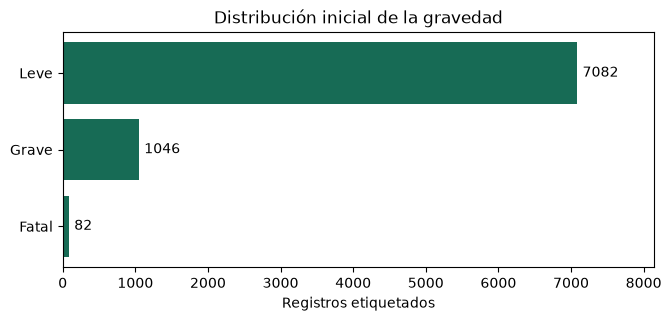

,Faltantes
Type_of_vehicle,652
Driving_experience,545
Area_accident_occured,160
Road_surface_type,115
Type_of_collision,100
Day_of_week,0
Time,0
Light_conditions,0
Road_surface_conditions,0
Weather_conditions,0


In [3]:
raw = pd.read_csv(source, encoding="utf-8-sig", low_memory=False)
print(f"Dimensiones del CSV etiquetado: {raw.shape[0]:,} filas × {raw.shape[1]} columnas")
counts_raw = raw[TARGET].value_counts().reindex(LABELS)
display(counts_raw.rename("Registros").to_frame())

fig, ax = plt.subplots(figsize=(6.6, 3.1), layout="constrained")
bars = ax.barh(["Leve", "Grave", "Fatal"], counts_raw, color="#176b55")
ax.bar_label(bars, padding=4)
ax.margins(x=0.15)
ax.invert_yaxis()
ax.set(xlabel="Registros etiquetados", title="Distribución inicial de la gravedad")
plt.show()

missing = raw[FIELDS].isna().sum().sort_values(ascending=False)
display(missing.rename("Faltantes").to_frame())

## 3. Limpieza y selección de variables

Normalizamos textos y etiquetas, convertimos la hora y validamos los conteos. Eliminamos duplicados con las mismas entradas preparadas y la misma etiqueta. Usamos 13 entradas del reporte y excluimos campos como **Casualty_severity**, que anticiparían la gravedad. Los faltantes válidos se imputan más adelante dentro del pipeline.

In [4]:
def prepare(frame):
    clean = frame[FIELDS].copy()
    for field in CATEGORIES:
        clean[field] = clean[field].astype("string").str.strip().replace("", pd.NA).astype(object)
        clean[field] = clean[field].where(clean[field].notna(), float("nan"))
    hours = clean.pop("Time").astype("string").str.strip()
    parsed = hours.str.extract(r"^(\d{1,2}):[0-5]\d(?::[0-5]\d)?$")[0]
    clean["Hour"] = pd.to_numeric(parsed, errors="coerce").astype(float)
    clean["Hour"] = clean["Hour"].where(clean["Hour"].between(0, 23))
    for field in NUMERIC[1:]:
        values = pd.to_numeric(clean[field], errors="coerce").astype(float)
        minimum = 1 if field == "Number_of_vehicles_involved" else 0
        clean[field] = values.where(values.between(minimum, 1000) & (values % 1 == 0))
    return clean


def read_training(path):
    raw = pd.read_csv(path, encoding="utf-8-sig", low_memory=False, nrows=100001)
    if len(raw) > 100000:
        raise ValueError("El CSV admite hasta 100 000 filas.")
    missing = set(FIELDS + [TARGET]).difference(raw.columns)
    if missing:
        raise ValueError("Columnas requeridas: " + ", ".join(sorted(missing)))
    y = raw[TARGET].astype("string").str.strip().str.lower().map({label.lower(): label for label in LABELS})
    if y.isna().any():
        raise ValueError("Cada fila debe contener una clase válida en Accident_severity.")
    x = prepare(raw)
    for field in FIELDS:
        source = raw[field].astype("string").str.strip().fillna("")
        column = "Hour" if field == "Time" else field
        if (source.ne("") & x[column].isna()).any():
            raise ValueError(f"Hay un valor inválido en {field}.")
    combined = x.assign(**{TARGET: y}).drop_duplicates()
    y = combined.pop(TARGET)
    if len(combined) < 150 or any(y.value_counts().get(label, 0) < 15 for label in LABELS):
        raise ValueError("Se requieren al menos 150 filas distintas y 15 por clase.")
    return combined.reset_index(drop=True), y.reset_index(drop=True)

In [5]:
x, y = read_training(source)
print(f"Registros después de limpiar: {len(y):,}")
print(f"Filas duplicadas eliminadas: {len(raw) - len(y):,}")
display(y.value_counts().rename("Registros distintos").reindex(LABELS).to_frame())

Registros después de limpiar: 8,159
Filas duplicadas eliminadas: 51


,Registros distintos
Accident_severity,
Slight Injury,7034
Serious Injury,1043
Fatal injury,82


## 4. División de desarrollo y prueba

Reservamos una partición para evaluar el modelo final. La división intenta conservar la proporción de clases y mantiene juntas las entradas preparadas idénticas. Después usamos solo el conjunto de desarrollo para comparar los modelos y ajustar su regla de decisión.

In [6]:
def identify(x):
    return pd.util.hash_pandas_object(x, index=False)

x, y = read_training(reference)
groups = identify(x)
split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_ids, test_ids = next(split.split(x, y, groups))
test_x, test_y = x.iloc[test_ids], y.iloc[test_ids]
fit_x, fit_y = x.iloc[train_ids], y.iloc[train_ids]
assert not set(groups.iloc[train_ids]).intersection(groups.iloc[test_ids])
distribution = pd.DataFrame({"Desarrollo": fit_y.value_counts(), "Prueba": test_y.value_counts()})
display(distribution.reindex(LABELS))
print(f"Desarrollo: {len(fit_x):,} registros. Prueba: {len(test_x):,} registros.")

,Desarrollo,Prueba
Accident_severity,,
Slight Injury,5627,1407
Serious Injury,835,208
Fatal injury,65,17


Desarrollo: 6,527 registros. Prueba: 1,632 registros.


## 5. Pipelines, modelos y ajuste de decisión

Comparamos cinco candidatos. La imputación, la codificación de categorías y el escalado numérico se aprenden dentro de cada partición. La regla de decisión multiplica los puntajes de clase por factores elegidos a partir de las predicciones fuera de muestra del conjunto de desarrollo. Los puntajes resultantes se normalizan.

In [7]:
def candidates():
    categorical = make_pipeline(SimpleImputer(strategy="constant", fill_value="Sin dato"), OneHotEncoder(handle_unknown="ignore"))
    ordinal = make_pipeline(SimpleImputer(strategy="constant", fill_value="Sin dato"),
                            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
    numeric = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler())
    encoding = ColumnTransformer([("numeric", numeric, NUMERIC), ("categorical", categorical, CATEGORIES)])
    dense = ColumnTransformer([("numeric", numeric, NUMERIC), ("categorical", ordinal, CATEGORIES)])
    return {
        "Regresión logística balanceada": make_pipeline(encoding, LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
        "Bosque aleatorio balanceado": make_pipeline(encoding, RandomForestClassifier(n_estimators=120, min_samples_leaf=4,
                                                                                      class_weight="balanced", random_state=SEED, n_jobs=2)),
        "Bosque aleatorio balanceado de hojas pequeñas": make_pipeline(encoding, RandomForestClassifier(
            n_estimators=280, min_samples_leaf=1, max_features=0.65, class_weight="balanced", random_state=SEED, n_jobs=2)),
        "Bosque aleatorio con ajuste de decisión": make_pipeline(encoding, RandomForestClassifier(
            n_estimators=280, min_samples_leaf=2, max_features=0.65, random_state=SEED, n_jobs=2)),
        "Gradient boosting balanceado": make_pipeline(dense, HistGradientBoostingClassifier(categorical_features=list(range(3, 3 + len(CATEGORIES))),
                                                                                           class_weight="balanced", random_state=SEED, max_iter=90)),
    }


def adjust_decision(probabilities, factors):
    scores = probabilities * factors
    return scores / scores.sum(axis=1, keepdims=True)


def tune_decision(y, probabilities, classes):
    """Choose decision multipliers from out-of-fold predictions only."""
    expected = np.searchsorted(classes, y)
    counts = np.bincount(expected, minlength=len(classes))
    alternatives = [np.ones(len(classes))]
    grid = np.geomspace(0.25, 6, 17)
    # Keep the common class as the scale reference and vary the two minority classes.
    alternatives.extend(np.array([fatal, serious, 1.0]) for fatal in grid for serious in grid)

    def score(factors):
        predictions = np.argmax(probabilities * factors, axis=1)
        correct = expected == predictions
        hits = np.bincount(expected[correct], minlength=len(classes))
        predicted = np.bincount(predictions, minlength=len(classes))
        return float(np.mean(2 * hits / (counts + predicted)))

    factors = max(alternatives, key=score)
    return factors, score(factors), score(alternatives[0])

In [8]:
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
models = candidates()
classes = np.array(sorted(LABELS))
training_groups = identify(fit_x)
validation, unadjusted, factors_by_model = {}, {}, {}
for name, model in models.items():
    out_of_fold = cross_val_predict(model, fit_x, fit_y, groups=training_groups, cv=cv, method="predict_proba")
    factors_by_model[name], validation[name], unadjusted[name] = tune_decision(fit_y, out_of_fold, classes)
comparison = pd.DataFrame({"F1 macro sin ajuste": unadjusted, "F1 macro ajustado": validation})
display(comparison.sort_values("F1 macro ajustado", ascending=False).round(4))

,F1 macro sin ajuste,F1 macro ajustado
Bosque aleatorio con ajuste de decisión,0.3607,0.5578
Bosque aleatorio balanceado de hojas pequeñas,0.5193,0.5202
Bosque aleatorio balanceado,0.4601,0.4914
Gradient boosting balanceado,0.4519,0.4694
Regresión logística balanceada,0.3049,0.3680


## 6. Entrenamiento final y evaluación

Ajustamos el candidato ganador con todo el conjunto de desarrollo y medimos su rendimiento en la prueba reservada. La línea base asigna siempre la clase más frecuente. El F1 macro promedia las tres clases por igual y la matriz permite ver qué errores cometió el modelo.

In [9]:
name = max(validation, key=validation.get)
estimator = models[name].fit(fit_x, fit_y)
factors = factors_by_model[name]
scores = adjust_decision(estimator.predict_proba(test_x), factors)
predicted = classes[np.argmax(scores, axis=1)]
baseline = DummyClassifier(strategy="most_frequent").fit(fit_x, fit_y).predict(test_x)
metrics = {
    "algorithm": name,
    "accuracy": accuracy_score(test_y, predicted),
    "balancedAccuracy": balanced_accuracy_score(test_y, predicted),
    "macroF1": f1_score(test_y, predicted, average="macro"),
    "baselineMacroF1": f1_score(test_y, baseline, average="macro"),
    "labels": LABELS,
    "perClass": {label: entry for label, entry in classification_report(
        test_y, predicted, labels=LABELS, output_dict=True, zero_division=0).items() if label in LABELS},
    "confusionMatrix": confusion_matrix(test_y, predicted, labels=LABELS).tolist(),
    "validationMacroF1": validation,
    "validationUnadjustedMacroF1": unadjusted,
    "decisionFactors": dict(zip(classes, factors.tolist())),
    "trainRows": len(fit_x),
    "testRows": len(test_x),
    "testClassCounts": test_y.value_counts().to_dict(),
    "sourceSha256": hashlib.sha256(source.read_bytes()).hexdigest(),
    "referenceSha256": hashlib.sha256(reference.read_bytes()).hexdigest(),
    "sklearnVersion": sklearn.__version__,
    "seed": SEED,
}
print(f"Modelo: {name}")
print(f"F1 macro: {metrics['macroF1']:.2%}")
print(f"F1 macro de la línea base: {metrics['baselineMacroF1']:.2%}")
print(f"Exactitud: {metrics['accuracy']:.2%}")
print(f"Exactitud balanceada: {metrics['balancedAccuracy']:.2%}")
display(pd.Series(metrics["decisionFactors"], name="Factor de decisión").to_frame())
display(pd.DataFrame(metrics["perClass"]).transpose().rename(
    columns={"precision": "Precisión", "recall": "Sensibilidad", "f1-score": "F1", "support": "Casos"}
).round(4))

Modelo: Bosque aleatorio con ajuste de decisión
F1 macro: 54.90%
F1 macro de la línea base: 30.87%
Exactitud: 82.84%
Exactitud balanceada: 52.64%


,Factor de decisión
Fatal injury,6.000000
Serious Injury,3.306448
Slight Injury,1.000000


,Precisión,Sensibilidad,F1,Casos
Slight Injury,0.9031,0.9005,0.9018,1407.0
Serious Injury,0.3653,0.3846,0.3747,208.0
Fatal injury,0.5000,0.2941,0.3704,17.0


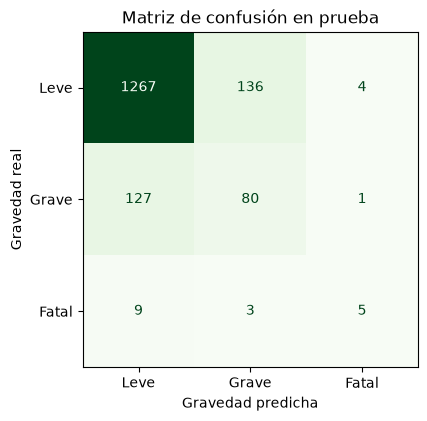

In [10]:
fig, ax = plt.subplots(figsize=(5.0, 4.1), layout="constrained")
matrix = ConfusionMatrixDisplay(np.asarray(metrics["confusionMatrix"]), display_labels=["Leve", "Grave", "Fatal"])
matrix.plot(ax=ax, colorbar=False, cmap="Greens", values_format="d")
ax.set(xlabel="Gravedad predicha", ylabel="Gravedad real", title="Matriz de confusión en prueba")
plt.show()

**Lectura de los resultados.** Con el CSV de referencia, ref-v2 obtiene 54,90 % de F1 macro. Detecta 5 de 17 casos fatales en la prueba. La sensibilidad de esa clase y el pequeño número de casos observados limitan la interpretación del resultado.

## 7. Exportación y predicción de ejemplo

Se guardan model.joblib con el pipeline y la regla de decisión, y report.json con las métricas. La última celda vuelve a abrir ese archivo y clasifica un ejemplo. Esta salida va a la carpeta del notebook indicada abajo, separada de los archivos que carga la API.

In [11]:
out = OUTPUT_DIR
levels = {field: sorted(fit_x[field].dropna().unique().tolist()) for field in CATEGORIES}
out.mkdir(parents=True, exist_ok=True)
joblib.dump({"estimator": estimator, "decisionFactors": factors}, out / "model.joblib", compress=3)
(out / "report.json").write_text(json.dumps({"metrics": metrics, "options": levels}, ensure_ascii=False, indent=2), encoding="utf-8")
print("Modelo exportado:", out / "model.joblib")
print("Reporte exportado:", out / "report.json")

Modelo exportado: resultados-notebook\model.joblib
Reporte exportado: resultados-notebook\report.json


In [12]:
def predict(path, payload):
    artifact = joblib.load(path)
    row = prepare(pd.DataFrame([payload]))
    estimator = artifact["estimator"] if isinstance(artifact, dict) else artifact
    scores = estimator.predict_proba(row)
    if isinstance(artifact, dict):
        scores = adjust_decision(scores, artifact["decisionFactors"])
    predicted = estimator.classes_[np.argmax(scores[0])]
    probabilities = dict(zip(estimator.classes_, scores[0]))
    return {"category": predicted, "probabilities": probabilities}

example = {field["name"]: field["example"] for field in FEATURES}
result = predict(out / "model.joblib", example)
print(f"Clase predicha: {result['category']}")
display(pd.Series(result["probabilities"], name="Puntaje normalizado").to_frame())

Clase predicha: Slight Injury


,Puntaje normalizado
Fatal injury,0.012227
Serious Injury,0.209238
Slight Injury,0.778534
